# 01. 데이터 전처리 · 시각화
**교실(학습) 환경 조절기 — 20713 김호준**

장치(ESP32)가 10초마다 Firebase에 올린 센서 기록(`logs_*.csv`)과 웹앱에서 사람이 남긴 라벨(`labels_*.csv`)을 정리한다.

| 단계 | 내용 |
|---|---|
| 1 | 불러오기 · 중복 제거 · 시간 정렬 |
| 2 | CO₂ 센서 예열 구간 제거, 측정 범위 밖 값 제거 |
| 3 | **UART와 PWM 두 방식의 CO₂ 값 비교 → 센서 신뢰성 검증** |
| 4 | 숨이 센서에 직접 닿아 생긴 순간 급등(이상값) 찾기 |
| 5 | 측정 끊김(공백) 찾아 연속 구간 나누기, 외출(빈 방) 구간 표시 |
| 6 | 장치와 똑같은 방식의 10분 특징 계산 |
| 7 | 라벨 붙이기(라벨 직전 20분) → 학습용 표 저장 |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as md
from common import *

logs = read_csvs("logs")
labels = read_csvs("labels")
logs["time"] = pd.to_datetime(logs["ts"], unit="s", utc=True).dt.tz_convert("Asia/Seoul")
labels["time"] = pd.to_datetime(labels["ts"], unit="s", utc=True).dt.tz_convert("Asia/Seoul")
print(f"센서 기록 {len(logs):,}개  ({logs.time.min():%m-%d %H:%M} ~ {logs.time.max():%m-%d %H:%M})")
print(f"라벨 {len(labels)}개")
logs.head()

센서 기록 8,568개  (11-14 13:20 ~ 11-15 13:18)
라벨 9개


,time,ts,up,flag,co2,co2_pwm,temp,hum,lux,snd_mean,snd_std,snd_max,snd_spikes,snd_sp,snd_flat,snd_cent,reed,state,vent,win
0,2026-11-14 13:20:24+09:00,1794630024,11,warmup,NaN,NaN,22.24,68.19,60.8,905.0,1070.0,4095,1,NaN,NaN,NaN,NaN,2,False,False
1,2026-11-14 13:20:34+09:00,1794630034,21,warmup,NaN,NaN,22.25,68.25,60.1,873.7,1154.5,4095,3,NaN,NaN,NaN,NaN,2,False,False
2,2026-11-14 13:20:44+09:00,1794630044,31,warmup,NaN,NaN,22.28,68.28,287.1,556.6,845.8,4095,1,NaN,NaN,NaN,NaN,2,False,False
3,2026-11-14 13:20:54+09:00,1794630054,41,warmup,NaN,NaN,22.34,68.43,151.0,537.4,804.3,4095,2,NaN,NaN,NaN,NaN,2,False,False
4,2026-11-14 13:21:04+09:00,1794630064,51,warmup,NaN,NaN,22.39,68.33,72.6,462.5,619.1,4095,2,NaN,NaN,NaN,NaN,0,False,False


## 2. 예열 구간 · 범위 밖 값 제거
MH-Z19C는 켜고 3분 동안 값이 불안정해서 장치가 `flag = warmup`으로 표시한다. CO₂는 400~5000ppm 밖이면 측정 오류로 본다.

In [2]:
n0 = len(logs)
logs.loc[logs["flag"] == "warmup", ["co2", "co2_pwm"]] = np.nan
bad = ~logs["co2"].between(400, 5000)
logs.loc[bad, "co2"] = np.nan
logs.loc[~logs["co2_pwm"].between(400, 5000), "co2_pwm"] = np.nan
print(f"예열 기록 {(logs.flag=='warmup').sum()}개, CO₂ 범위 밖 {bad.sum()}개 → CO₂만 결측 처리")
clip = (logs["snd_max"] >= 4095).sum()
print(f"소리 최댓값이 측정 한계(4095)에 닿은 기록: {clip}개 ({clip/len(logs)*100:.1f}%) — 큰 소리에서 파형이 잘림")

예열 기록 50개, CO₂ 범위 밖 50개 → CO₂만 결측 처리
소리 최댓값이 측정 한계(4095)에 닿은 기록: 92개 (1.1%) — 큰 소리에서 파형이 잘림


## 3. CO₂ 센서 신뢰성 검증: UART vs PWM
같은 센서의 값을 **서로 다른 두 통신 방식**(디지털 UART 명령, PWM 펄스 길이)으로 동시에 읽었다. 두 값이 일치하면 통신·계산 오류가 없다는 근거가 된다.

비교 기록 8,518개 | 평균 차이 -0.5 ppm | 차이 표준편차 2.9 ppm | 평균 절대 차이 0.8 ppm | 상관계수 r = 1.0000


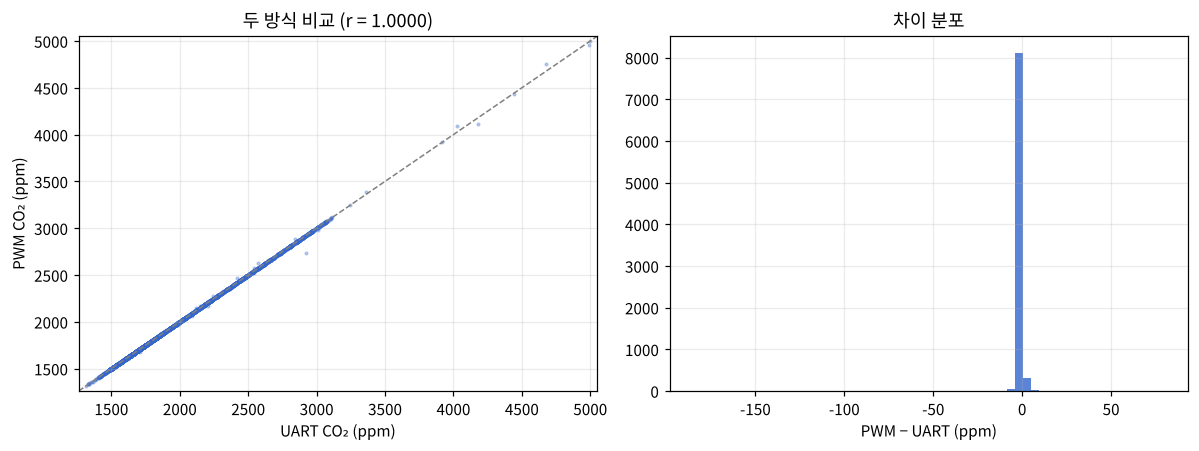

In [3]:
both = logs.dropna(subset=["co2", "co2_pwm"])
diff = both["co2_pwm"] - both["co2"]
r = np.corrcoef(both["co2"], both["co2_pwm"])[0, 1]
print(f"비교 기록 {len(both):,}개 | 평균 차이 {diff.mean():+.1f} ppm | 차이 표준편차 {diff.std():.1f} ppm | "
      f"평균 절대 차이 {diff.abs().mean():.1f} ppm | 상관계수 r = {r:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(both["co2"], both["co2_pwm"], s=3, alpha=.3, color="#3366cc")
lim = [both["co2"].min() - 50, both["co2"].max() + 50]
ax[0].plot(lim, lim, "--", color="gray", lw=1); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("UART CO₂ (ppm)"); ax[0].set_ylabel("PWM CO₂ (ppm)"); ax[0].set_title(f"두 방식 비교 (r = {r:.4f})")
ax[1].hist(diff, bins=60, color="#3366cc", alpha=.8); ax[1].set_xlabel("PWM − UART (ppm)"); ax[1].set_title("차이 분포")
for a in ax: a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{RES}/01_co2_uart_vs_pwm.png", dpi=150); plt.show()

## 4. 숨이 직접 닿아 생긴 순간 급등 찾기
마이크 테스트 때 장치 가까이에서 말하자 CO₂가 10초 만에 수백 ppm 뛰었다가 바로 돌아왔다. 방 전체 공기가 아니라 **날숨이 센서에 직접 닿은 것**이므로, 주변 2분(앞뒤 6개) 중앙값보다 250ppm 이상 높은 기록은 이상값으로 표시하고 중앙값으로 바꾼다.

In [4]:
med = logs["co2"].rolling(13, center=True, min_periods=5).median()
spike = (logs["co2"] - med) > 250
logs["co2_raw"] = logs["co2"]
logs.loc[spike, "co2"] = med[spike]
print(f"날숨 급등으로 판단해 보정한 기록: {spike.sum()}개")

날숨 급등으로 판단해 보정한 기록: 15개


## 5. 측정 공백 · 연속 구간 · 외출 구간
기록 간격이 60초를 넘으면 장치가 꺼졌거나 와이파이가 끊긴 것으로 보고 구간을 나눈다. 11/14 17:00~21:20은 사용자가 외출해 **방이 비어 있던 시간**이다(사람 없음 → CO₂가 어떻게 줄어드는지 비교용).

In [5]:
gap = logs["ts"].diff().fillna(10) > 60
logs["seg"] = gap.cumsum()
segs = logs.groupby("seg").agg(start=("time", "min"), end=("time", "max"), n=("ts", "size"))
print(segs.to_string())
ABSENT = [("2026-11-14 17:00", "2026-11-14 21:20")]
logs["occupied"] = 1
for s, e in ABSENT:
    m = logs["time"].between(pd.Timestamp(s, tz="Asia/Seoul"), pd.Timestamp(e, tz="Asia/Seoul"))
    logs.loc[m, "occupied"] = 0
print(f"빈 방 기록 {(logs.occupied==0).sum():,}개")

                        start                       end     n
seg                                                          
0   2026-11-14 13:20:24+09:00 2026-11-14 13:42:59+09:00   132
1   2026-11-14 13:44:46+09:00 2026-11-15 13:18:23+09:00  8436
빈 방 기록 1,549개


## 전체 시간 흐름

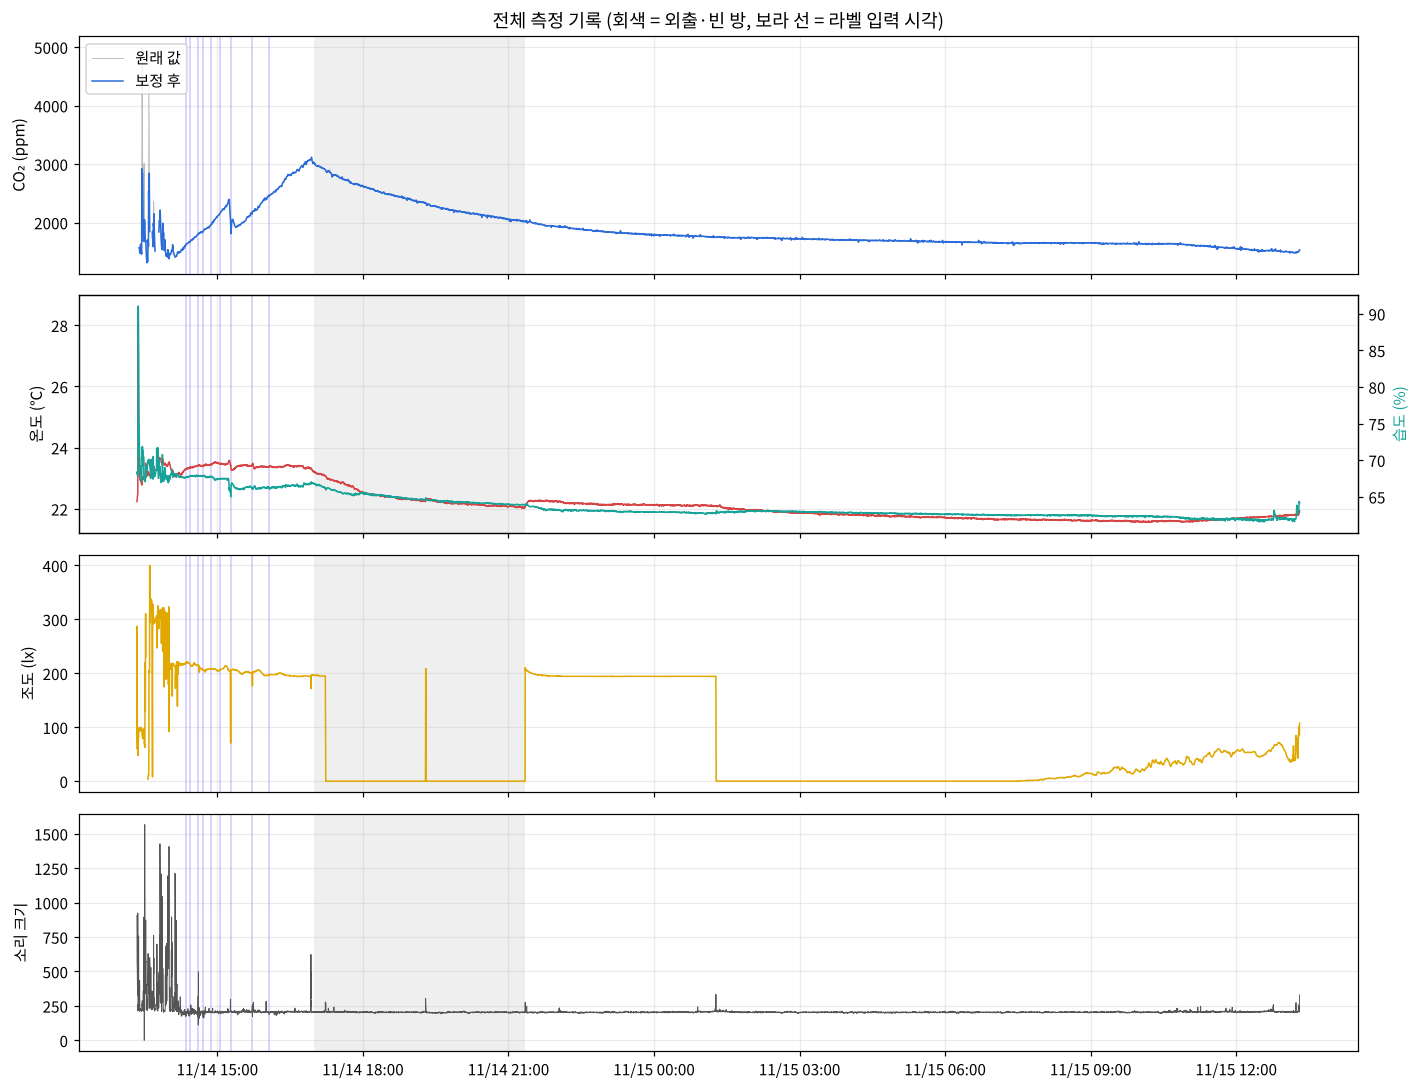

In [6]:
fig, ax = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
t = logs["time"]
for a in ax:
    for s, e in ABSENT: a.axvspan(pd.Timestamp(s, tz="Asia/Seoul"), pd.Timestamp(e, tz="Asia/Seoul"), color="#999", alpha=.15, lw=0)
    for _, L in labels.iterrows(): a.axvline(L["time"], color="#7b61ff", alpha=.35, lw=1)
ax[0].plot(t, logs["co2_raw"], color="#bbb", lw=.6, label="원래 값")
ax[0].plot(t, logs["co2"], color="#2b6cd8", lw=1, label="보정 후"); ax[0].set_ylabel("CO₂ (ppm)"); ax[0].legend(loc="upper left")
ax[1].plot(t, logs["temp"], color="#d64545", lw=1); ax[1].set_ylabel("온도 (℃)")
a2 = ax[1].twinx(); a2.plot(t, logs["hum"], color="#17a398", lw=1); a2.set_ylabel("습도 (%)", color="#17a398")
ax[2].plot(t, logs["lux"], color="#e0a800", lw=1); ax[2].set_ylabel("조도 (lx)")
ax[3].plot(t, logs["snd_mean"], color="#555", lw=.6); ax[3].set_ylabel("소리 크기")
ax[3].xaxis.set_major_formatter(md.DateFormatter("%m/%d %H:%M", tz="Asia/Seoul"))
ax[0].set_title("전체 측정 기록 (회색 = 외출·빈 방, 보라 선 = 라벨 입력 시각)")
for a in ax: a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{RES}/01_timeline.png", dpi=150); plt.show()

## 6. 장치와 같은 10분 특징 계산
펌웨어 `computeFeatures()`와 **똑같은 식**(최근 60개 기록의 평균·합·최소제곱 기울기)으로 계산해야, 학습한 모델을 장치에 넣었을 때 같은 입력을 받는다. 연속 구간마다 따로 계산한다.

In [7]:
feats = pd.concat([window_features(g) for _, g in logs.groupby("seg")])
data = pd.concat([logs, feats.add_prefix("f_")], axis=1)
data.head()

,time,ts,up,flag,co2,co2_pwm,temp,hum,lux,snd_mean,...,f_snd_std,f_snd_spikes,f_co2_mean,f_co2_slope,f_lux,f_temp,f_hum,f_snd_sp,f_snd_flat,f_snd_cent
0,2026-11-14 13:20:24+09:00,1794630024,11,warmup,NaN,NaN,22.24,68.19,60.8,905.0,...,1070.000000,1,NaN,0.0,60.80,22.240000,68.1900,NaN,NaN,NaN
1,2026-11-14 13:20:34+09:00,1794630034,21,warmup,NaN,NaN,22.25,68.25,60.1,873.7,...,1112.250000,4,NaN,0.0,60.45,22.245000,68.2200,NaN,NaN,NaN
2,2026-11-14 13:20:44+09:00,1794630044,31,warmup,NaN,NaN,22.28,68.28,287.1,556.6,...,1023.433333,5,NaN,0.0,136.00,22.256667,68.2400,NaN,NaN,NaN
3,2026-11-14 13:20:54+09:00,1794630054,41,warmup,NaN,NaN,22.34,68.43,151.0,537.4,...,968.650000,7,NaN,0.0,139.75,22.277500,68.2875,NaN,NaN,NaN
4,2026-11-14 13:21:04+09:00,1794630064,51,warmup,NaN,NaN,22.39,68.33,72.6,462.5,...,898.740000,9,NaN,0.0,126.32,22.300000,68.2960,NaN,NaN,NaN


## 7. 라벨 붙이기
라벨 하나는 **입력 직전 20분**(이전 라벨이 그보다 가까우면 그 이후)의 상태를 대표한다고 보고, 그 사이 10초 기록 전부에 같은 상태를 붙인다. 같은 라벨에서 나온 기록은 서로 비슷하므로 `group`으로 묶어 두고, 평가할 때 같은 묶음이 학습·시험에 동시에 들어가지 않게 한다(데이터 누수 방지).

상태 규칙: 졸림 ≥ 4 → **졸림**, 집중도 ≥ 4 → **최적**, 그 외 → **산만**

In [8]:
labels["state"] = [label_to_state(f, d) for f, d in zip(labels["focus"], labels["drowsy"])]
data["state_label"] = np.nan; data["group"] = -1
prev = None
for gi, L in labels.reset_index(drop=True).iterrows():
    start = L["ts"] - 20 * 60
    if prev is not None: start = max(start, prev)
    m = (data["ts"] > start) & (data["ts"] <= L["ts"]) & data["co2"].notna()
    data.loc[m, "state_label"] = L["state"]; data.loc[m, "group"] = gi
    prev = L["ts"]
lab = data[data["state_label"].notna()].copy()
lab["state_label"] = lab["state_label"].astype(int)
print(labels[["time", "focus", "drowsy", "sleeping", "note", "state"]].assign(상태=labels.state.map(STATE_KO)).to_string())
print("\n라벨이 붙은 10초 기록 수:", lab["state_label"].map(STATE_KO).value_counts().to_dict())

                       time  focus  drowsy  sleeping                   note  state  상태
0 2026-11-14 14:20:54+09:00      2       1         0  조용(이어폰 인강), 창문 닫음, 간식      2  산만
1 2026-11-14 14:26:38+09:00      3       2         0       조용/닫힘/인강/간식(배부름)      2  산만
2 2026-11-14 14:36:34+09:00      1       1         0                트림, 재채기      2  산만
3 2026-11-14 14:42:28+09:00      5       1         0             마우스 클릭 소리남      0  최적
4 2026-11-14 14:52:32+09:00      4       1         0                    NaN      0  최적
5 2026-11-14 15:03:15+09:00      4       1         0                    NaN      0  최적
6 2026-11-14 15:16:29+09:00      4       1         0         방 문 열고 화장실 다녀옴      0  최적
7 2026-11-14 15:43:19+09:00      4       1         0                    NaN      0  최적
8 2026-11-14 16:03:48+09:00      3       1         0                    NaN      2  산만

라벨이 붙은 10초 기록 수: {'최적': 358, '산만': 332}


## 상태별 센서 값 분포

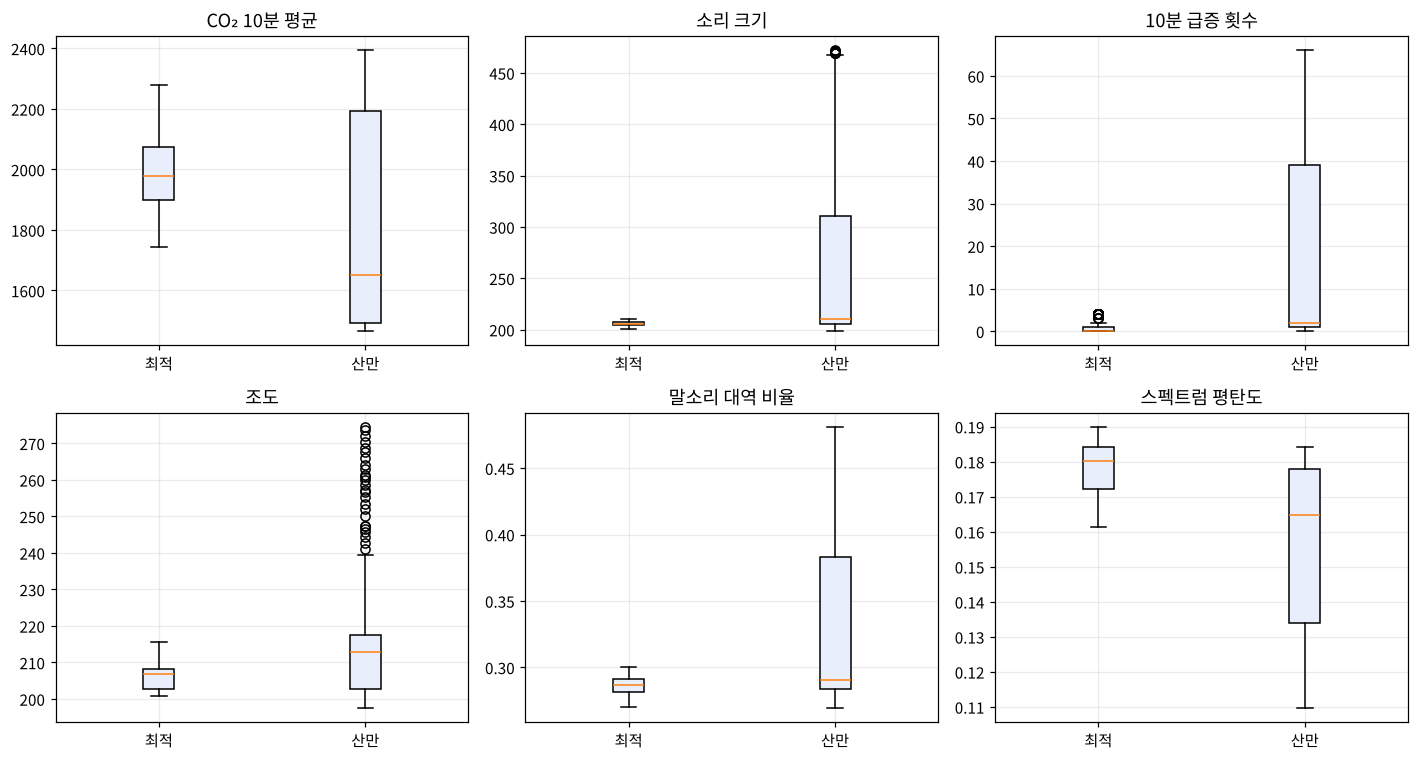

In [9]:
cols = [("f_co2_mean", "CO₂ 10분 평균"), ("f_snd_mean", "소리 크기"), ("f_snd_spikes", "10분 급증 횟수"),
        ("f_lux", "조도"), ("f_snd_sp", "말소리 대역 비율"), ("f_snd_flat", "스펙트럼 평탄도")]
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for a, (c, name) in zip(ax.flat, cols):
    st = sorted(lab["state_label"].unique())
    a.boxplot([lab.loc[lab.state_label == s, c].dropna() for s in st], tick_labels=[STATE_KO[s] for s in st],
              patch_artist=True, boxprops=dict(facecolor="#e8eefc"))
    a.set_title(name); a.grid(alpha=.25)
plt.tight_layout(); plt.savefig(f"{RES}/01_state_boxplot.png", dpi=150); plt.show()

## 특징 사이 상관관계

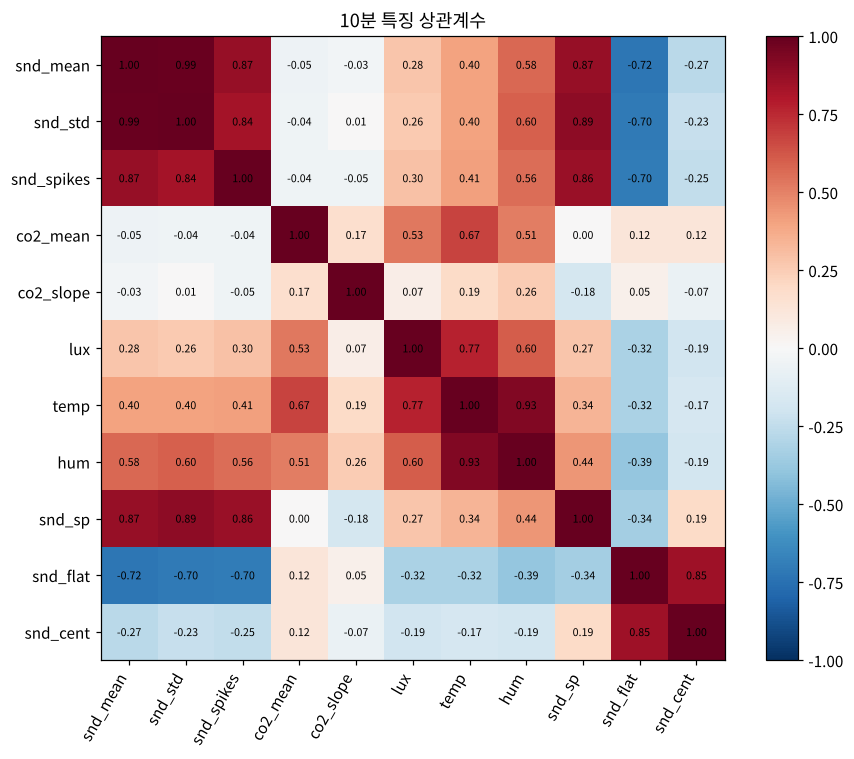

In [10]:
fc = ["f_" + c for c in BASE_FEATS + SPEC_FEATS]
corr = data[data.occupied == 1][fc].corr()
fig, a = plt.subplots(figsize=(8.5, 7))
im = a.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
a.set_xticks(range(len(fc))); a.set_xticklabels([c[2:] for c in fc], rotation=60, ha="right")
a.set_yticks(range(len(fc))); a.set_yticklabels([c[2:] for c in fc])
for i in range(len(fc)):
    for j in range(len(fc)): a.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, fraction=.046); a.set_title("10분 특징 상관계수")
plt.tight_layout(); plt.savefig(f"{RES}/01_corr.png", dpi=150); plt.show()

## 저장
- `data/processed/records_clean.csv` : 정리된 10초 기록 + 10분 특징 (전체)
- `data/processed/labeled.csv` : 라벨이 붙은 기록만 (상태 분류 학습용)
- `data/processed/co2_1min.csv` : 1분 평균 CO₂ (CO₂ 예측 학습용)

In [11]:
keep = ["time", "ts", "seg", "occupied", "co2", "co2_raw", "co2_pwm", "temp", "hum", "lux", "snd_mean", "snd_std",
        "snd_max", "snd_spikes", "snd_sp", "snd_flat", "snd_cent", "state"] + fc + ["state_label", "group"]
data[keep].to_csv(f"{PROC}/records_clean.csv", index=False, encoding="utf-8-sig")
lab[keep].to_csv(f"{PROC}/labeled.csv", index=False, encoding="utf-8-sig")
m1 = (data.set_index("time").groupby("seg")[["co2", "occupied"]].resample("1min").mean().reset_index())
m1.to_csv(f"{PROC}/co2_1min.csv", index=False, encoding="utf-8-sig")
print(f"저장 완료: 전체 {len(data):,}행, 라벨 {len(lab):,}행, 1분 CO₂ {len(m1):,}행")

저장 완료: 전체 8,568행, 라벨 690행, 1분 CO₂ 1,438행
